<center>
  <h3>More than a Hack 2027 &middot; Phase 1</h3>
  <h2>Frame-level Ball Possession &mdash; 004 Gap Classifier</h2>

  <p><strong>Metrica Sports &times; FC Barcelona Innovation Hub &times; Mobile World Capital</strong></p>
</center>

---

### Three Makasih

- **Anggota 1** (<span style="color:gray">email</span>)
- **Anggota 2** (<span style="color:gray">email</span>)
- **Anggota 3** (<span style="color:gray">email</span>)

---

## Ringkasan

Dua eksperimen sebelumnya gagal pada bola mati dengan cara berlawanan: 002 melabeli 38% frame sebagai `D` (semua gap ≥ 8 detik), 003 hanya 2% (detektor per frame terlalu lemah). Eksperimen ini mengubah satuan analisis dari **frame** menjadi **gap bola**: untuk tiap gap tanpa bola, dihitung apakah ia lebih mirip *bola keluar dan restart* atau *oklusi saat bermain*.

Eksplorasi menunjukkan bahwa gap yang dimulai atau berakhir dekat garis lapangan 2,4 kali lebih sering daripada kebetulan (34% vs 14%), dan gap di sekitar tag set piece 52 sampai 59% berdekatan dengan garis, dibandingkan 20 sampai 25% pada gap tanpa tag. Fitur gap (durasi, jarak ke garis di awal dan akhir, perpindahan bola, gerak pemain) dilatih terhadap **pseudo-label algoritmik**: gap dekat tag set piece dianggap restart. Tag **tidak** dipakai sebagai fitur, jadi detektor bisa menggeneralisasi ke gap tanpa tag.

Tidak ada label tangan dan ground truth tidak dipakai.


# Metodologi

**ATD → daftar gap bola per babak → fitur gap → pseudo-label dari tag set piece → klasifikasi gap (regresi logistik, validasi silang antar babak) → gap mati menjadi `D` → Viterbi H/A (bukti tim 002) → `out/*.csv` → validasi → skor GT publik (hanya pemeriksaan pipeline).**

| asumsi | nilai | alasan |
|---|---|---|
| gap dianalisis | durasi ≥ 2 detik, di dalam babak | gap lebih pendek hampir pasti oklusi singkat |
| pseudo-label positif | ada awal set piece dalam [awal gap − 5 dtk, akhir gap + 5 dtk] | tag set piece menandai restart |
| ambang keputusan | p ≥ 0,5 setelah koreksi prior | prior = porsi gap bertag; bukan hasil tuning pada GT |
| τ, λ | 3 m, 50 nat | prior, sama seperti 002 |

# Environment

Dijalankan dari dalam repositori. Seluruh pemrosesan lokal; tidak ada data pertandingan yang meninggalkan mesin.

In [1]:
from pathlib import Path
import sys

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "games.py").exists())
for p in (ROOT, ROOT / "starter", ROOT / "evaluation", ROOT / "experiments"):
    sys.path.insert(0, str(p))

import subprocess
import warnings
warnings.filterwarnings("ignore")
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

import common
from baseline import smooth, write_submission
from games import GAME, GAMES, anchor_video_frame, half_video_blocks, source_frames
from load_smart_tagging import load as load_tags

C1, C2, C3, INK, GREY = "#e94f37", "#393e41", "#f6f7eb", "#393e41", "#a3a7a6"
mpl.rcParams.update({
    "figure.facecolor": C3, "savefig.facecolor": C3, "axes.facecolor": "white",
    "axes.edgecolor": INK, "axes.labelcolor": INK, "text.color": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.titleweight": "bold", "axes.titlesize": 10, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False, "legend.frameon": False,
    "figure.dpi": 110, "axes.prop_cycle": mpl.cycler(color=[C1, C2, GREY]),
})
def panel(ax, l): ax.text(-0.09, 1.07, l, transform=ax.transAxes, fontsize=12, fontweight="bold", va="top")

FPS = 25; LEN, WID = 105.3, 68.0
N = source_frames("tactical")
BLOCKS = half_video_blocks("BAR-ATH")
GRADED = np.zeros(N, bool)
for _, a, b in BLOCKS: GRADED[a:b + 1] = True
OUT = Path(common.HERE) / "004_gap_classifier" / "out"; OUT.mkdir(parents=True, exist_ok=True)
KICKOFF2 = anchor_video_frame(GAMES[GAME]["kickoff_2nd"]) + 1
assert KICKOFF2 == 113742
print("frames:", N, "| dinilai:", GRADED.sum())

frames: 199319 | dinilai: 158857


# Approach: Klasifikasi Gap Bola

## [1] Daftar gap dan fiturnya

Gap adalah deretan frame berurutan tanpa bola di dalam satu babak. Untuk tiap gap, dari posisi bola terakhir sebelum dan pertama sesudah gap:

- `log durasi`
- `jarak ke garis di awal` dan `di akhir` (meter, negatif = di luar garis)
- `log perpindahan` antara posisi sebelum dan sesudah, dan `kecepatan implisit` (perpindahan / durasi): bola mati cenderung kembali ke titik yang dekat, bola yang sedang dimainkan berpindah jauh
- `kecepatan median pemain` dan `proporsi bergerak` selama gap

In [2]:
P, B, T = common.load_atd_arrays()
bx, by = B[:, 0] * LEN, B[:, 1] * WID
vis = np.isfinite(bx)
spd = P[..., 2]; fin = np.isfinite(spd); nf = fin.sum(1)
med = np.where(nf > 0, np.nanmedian(np.where(fin, spd, np.nan), axis=1), np.nan)
mov = np.where(nf > 0, (np.where(fin, spd, 0) > 1.5).sum(1) / np.maximum(nf, 1), np.nan)

def bdist(i):
    return min(bx[i], LEN - bx[i], by[i], WID - by[i])

tags = pd.DataFrame([{**{k: v for k, v in t.items() if k != "tags"}, **t["tags"]} for t in load_tags()])
sp_start = tags[tags.code == "SET PIECES"].start_frame.values

rows = []
for half, a, b in BLOCKS:
    s, e = common.runs(~vis[a:b + 1])
    for si, ei in zip(s, e):
        f0, f1 = a + si - 1, a + ei
        if f0 < a or f1 > b: continue                      # gap menyentuh batas babak: lewati
        dur = (ei - si) / FPS
        disp = float(np.hypot(bx[f1] - bx[f0], by[f1] - by[f0]))
        rows.append({"half": half, "f0": a + si, "f1": a + ei, "dur": dur,
                     "d_start": bdist(f0), "d_end": bdist(f1), "disp": disp, "v_imp": disp / dur,
                     "spd": np.nanmean(med[a + si:a + ei]), "mov": np.nanmean(mov[a + si:a + ei]),
                     "tag": bool(((sp_start >= f0 - 5 * FPS) & (sp_start <= f1 + 5 * FPS)).any())})
G = pd.DataFrame(rows)
LONG = G[G.dur >= 2].reset_index(drop=True)
print(f"gap total: {len(G)} | gap >= 2 dtk: {len(LONG)} | bertag set piece di dekatnya: {LONG.tag.mean():.1%}")
print(f"frame dalam gap >= 2 dtk: {LONG.dur.sum() * FPS / GRADED.sum():.1%} dari frame dinilai")
display(LONG.groupby("tag")[["dur", "d_start", "d_end", "disp", "v_imp", "spd", "mov"]].median().round(2))

gap total: 147 | gap >= 2 dtk: 131 | bertag set piece di dekatnya: 35.1%
frame dalam gap >= 2 dtk: 40.3% dari frame dinilai


,dur,d_start,d_end,disp,v_imp,spd,mov
tag,,,,,,,
False,9.28,7.93,8.82,9.81,0.77,1.29,0.32
True,22.34,2.55,0.64,16.18,0.65,1.05,0.21


Gap bertag (baris `True`) berdurasi lebih dari dua kali lipat (22,3 vs 9,3 detik), dimulai dan berakhir jauh lebih dekat ke garis (2,6 m dan 0,6 m vs 7,9 m dan 8,8 m), serta pemain bergerak lebih lambat. Perpindahan bola justru lebih besar (16,2 vs 9,8 m), tetapi kecepatan implisitnya lebih rendah karena gapnya lebih lama. Perbedaan median ini adalah dasar klasifikasi.

## [2] Pseudo-label dan klasifikasi

Regresi logistik berbobot-seimbang dengan validasi silang **antar babak**. Karena jumlah gap kecil (puluhan per babak), AUC bersifat kasar; ini pemeriksaan konsistensi, bukan estimasi akurasi.

,latih,uji,AUC,n gap uji,n bertag
0,babak 1,babak 2,0.796,72,26
1,babak 2,babak 1,0.864,59,20


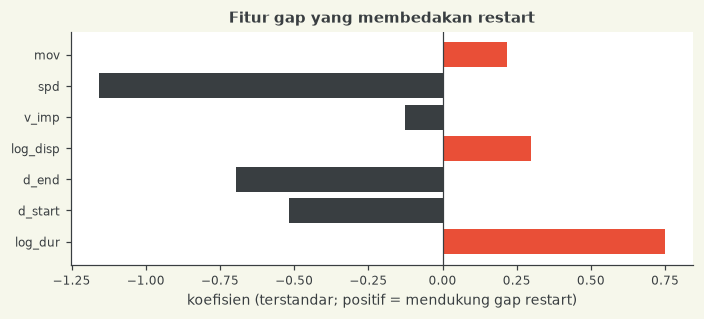

In [3]:
FEATS = ["log_dur", "d_start", "d_end", "log_disp", "v_imp", "spd", "mov"]
def make_X(df):
    return pd.DataFrame({"log_dur": np.log(df.dur), "d_start": df.d_start.clip(-5, 40), "d_end": df.d_end.clip(-5, 40),
                         "log_disp": np.log1p(df.disp), "v_imp": df.v_imp.clip(0, 30),
                         "spd": df.spd.fillna(df.spd.median()), "mov": df.mov.fillna(df.mov.median())})
X, y = make_X(LONG), LONG.tag.astype(int).values
mk = lambda: make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000))

cv = []
for tr_h, te_h in ((1, 2), (2, 1)):
    tr, te = (LONG.half == tr_h).values, (LONG.half == te_h).values
    m = mk().fit(X[tr], y[tr]); pr = m.predict_proba(X[te])[:, 1]
    cv.append({"latih": f"babak {tr_h}", "uji": f"babak {te_h}", "AUC": roc_auc_score(y[te], pr), "n gap uji": int(te.sum()), "n bertag": int(y[te].sum())})
display(pd.DataFrame(cv).round(3))

MODEL = mk().fit(X, y)
coef = pd.Series(MODEL[-1].coef_[0], index=FEATS)
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.barh(coef.index, coef.values, color=[C1 if v > 0 else C2 for v in coef.values]); ax.axvline(0, color=INK, lw=0.8)
ax.set(xlabel="koefisien (terstandar; positif = mendukung gap restart)", title="Fitur gap yang membedakan restart"); fig.tight_layout(); plt.show()

AUC antar babak 0,80 dan 0,86, dan arah koefisien masuk akal: gap lebih panjang, lebih dekat ke garis di awal dan akhir, dan dengan pemain bergerak lebih lambat lebih mungkin restart. **Bias yang perlu diingat:** label positif didefinisikan dengan jendela ±5 detik di sekitar gap, sehingga gap yang lebih panjang lebih mudah tumpang tindih dengan tag secara kebetulan. Koefisien durasi (terbesar) sebagian mencerminkan bias pelabelan ini, bukan hanya fisika bola mati. AUC juga dihitung terhadap pseudo-label itu sendiri.

## [3] Probabilitas gap mati

Probabilitas model berbobot-seimbang dikoreksi ke prior porsi gap bertag, lalu gap dengan $p \ge \theta$ dianggap mati.

prior (porsi gap bertag): 0.351
theta 0.35: gap mati 60 dari 131 | frame D 28.3% dari frame dinilai | di antaranya bertag 63%
theta 0.5: gap mati 37 dari 131 | frame D 20.8% dari frame dinilai | di antaranya bertag 76%
theta 0.65: gap mati 25 dari 131 | frame D 17.6% dari frame dinilai | di antaranya bertag 80%


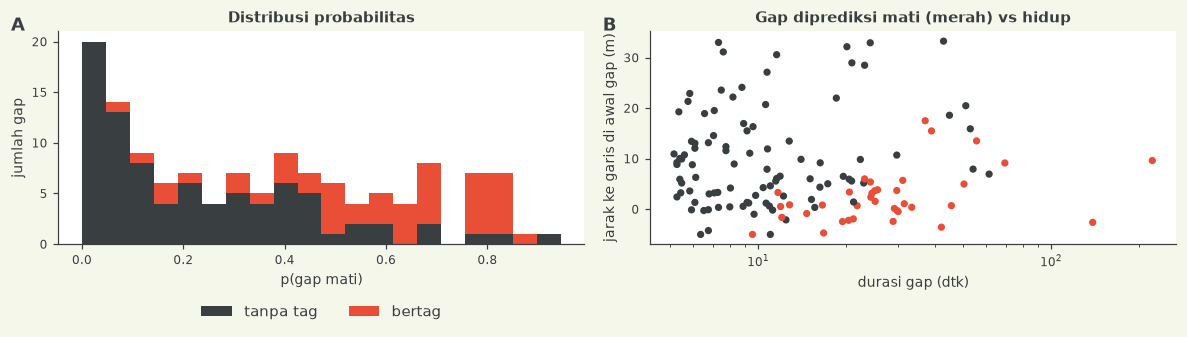

In [4]:
prior = y.mean()
pb = np.clip(MODEL.predict_proba(X)[:, 1], 1e-6, 1 - 1e-6)
logit = np.log(pb / (1 - pb)) + np.log(prior / (1 - prior))
LONG["p_dead"] = 1 / (1 + np.exp(-logit))
print(f"prior (porsi gap bertag): {prior:.3f}")
for th in (0.35, 0.5, 0.65):
    d = LONG[LONG.p_dead >= th]
    print(f"theta {th}: gap mati {len(d)} dari {len(LONG)} | frame D {d.dur.sum() * FPS / GRADED.sum():.1%} dari frame dinilai | di antaranya bertag {d.tag.mean():.0%}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
ax[0].hist([LONG.p_dead[~LONG.tag], LONG.p_dead[LONG.tag]], bins=20, stacked=True, color=[C2, C1], label=["tanpa tag", "bertag"])
ax[0].set(xlabel="p(gap mati)", ylabel="jumlah gap", title="Distribusi probabilitas")
ax[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2)
ax[1].scatter(LONG.dur, LONG.d_start.clip(-5, 40), c=np.where(LONG.p_dead >= 0.5, C1, C2), s=14)
ax[1].set(xscale="log", xlabel="durasi gap (dtk)", ylabel="jarak ke garis di awal gap (m)", title="Gap diprediksi mati (merah) vs hidup")
panel(ax[0], "A"); panel(ax[1], "B"); fig.tight_layout(); plt.show()

## [4] Decoder: Viterbi H/A dan gap mati menjadi `D`

Bukti tim sama dengan 002 (τ = 3 m, λ = 50). Gap yang diprediksi mati menimpa label dengan `D`. Gap pendek (< 2 detik) dan gap yang diprediksi hidup tetap mewarisi keadaan tim. Frame di luar babak adalah `X`, dan 2.934 frame pra-kick-off babak kedua adalah `D`.

In [5]:
TAU, LAM = 3.0, 50.0
dist = common.team_distances()
dH, dA = dist[:, 0], dist[:, 1]
OK = np.isfinite(dH) & np.isfinite(dA)
E = np.zeros(N); E[OK] = np.clip((dA[OK] - dH[OK]) / TAU, -10, 10)
LP_H, LP_A = -np.logaddexp(0, -E), -np.logaddexp(0, E); LP_H[~OK] = 0; LP_A[~OK] = 0

TEAM_PATH = {}
for half, a, b in BLOCKS:
    TEAM_PATH[half] = common.viterbi_2state(LP_H[a:b + 1], LP_A[a:b + 1], LAM)

def decode(theta=0.5, use_gap=True):
    labels = np.full(N, "X", dtype="<U1")
    for half, a, b in BLOCKS:
        labels[a:b + 1] = np.where(TEAM_PATH[half] == 0, "H", "A")
        if half == 2: labels[a:KICKOFF2] = "D"
    if use_gap:
        for _, r in LONG[LONG.p_dead >= theta].iterrows():
            labels[int(r.f0):int(r.f1)] = "D"
    return labels

def possessions(labels):
    n, durs = 0, []
    for _, a, b in BLOCKS:
        seg = labels[a:b + 1]
        for t in ("H", "A"):
            s, e = common.runs(seg == t); n += len(s); durs += list((e - s) / FPS)
    return n, float(np.mean(durs))

demo = decode()
print(pd.Series(demo[GRADED]).value_counts(normalize=True).round(3).to_string())
print("possession: %d | durasi rata-rata %.1f dtk" % possessions(demo))

H    0.407
A    0.366
D    0.227
possession: 191 | durasi rata-rata 25.7 dtk


## [5] Varian yang dibangun

Satu parameter berubah pada satu waktu (ambang θ), ditambah ablasi tanpa aturan gap (hanya pra-kick-off), aturan gap 002 (semua gap ≥ 8 detik), dan baseline `smooth50`.

In [6]:
VARIANTS = {"v1_theta50": decode(0.5), "v2_theta35": decode(0.35), "v3_theta65": decode(0.65),
            "v4_nogap": decode(use_gap=False)}
v002 = decode(use_gap=False)
for _, a, b in BLOCKS:
    s, e = common.runs(~vis[a:b + 1])
    for si, ei in zip(s, e):
        if (ei - si) >= 8 * FPS: v002[a + si:a + ei] = "D"
VARIANTS["ref_002_gap8"] = v002

for old in OUT.glob("*.csv"): old.unlink()
rows = []
for name, lab in VARIANTS.items():
    write_submission(str(OUT / f"{name}.csv"), lab)
    n, d = possessions(lab)
    rows.append({"varian": name, "possession": n, "durasi rata2 (dtk)": round(d, 1), "% D (dinilai)": round(100 * np.mean(lab[GRADED] == "D"), 1)})
codes = common.cached("atd_nearest", lambda: None)
base = np.full(N, "X", dtype="<U1"); sm = smooth(codes, 50)
for _, a, b in BLOCKS: base[a:b + 1] = sm[a:b + 1]
write_submission(str(OUT / "baseline_smooth50.csv"), base)
n, d = possessions(base)
rows.append({"varian": "baseline_smooth50", "possession": n, "durasi rata2 (dtk)": round(d, 1), "% D (dinilai)": round(100 * np.mean(base[GRADED] == "D"), 1)})
display(pd.DataFrame(rows))

,varian,possession,durasi rata2 (dtk),% D (dinilai)
0,v1_theta50,191,25.7,22.7
1,v2_theta35,212,21.0,30.0
2,v3_theta65,181,28.3,19.4
3,v4_nogap,159,39.2,1.8
4,ref_002_gap8,243,16.1,38.3
5,baseline_smooth50,594,7.2,32.3


## [6] Validasi dan skor (pemeriksaan pipeline)

Skor GT publik hanya memeriksa bahwa berkas benar. Dengan 17 possession, selisih kecil antar varian adalah noise dan tidak boleh dipakai untuk memilih varian.

In [7]:
for f in sorted(OUT.glob("*.csv")):
    r = subprocess.run([sys.executable, str(ROOT / "evaluation" / "validate_submission.py"), str(f)], capture_output=True, text=True)
    print(f.name, "->", "VALID" if "Valid." in r.stdout else r.stdout[-200:])
subprocess.run([sys.executable, str(ROOT / "evaluation" / "run_evaluation.py"), "--results", str(OUT), "--out", str(OUT / "reports")], capture_output=True, text=True)
board = pd.read_csv(OUT / "reports" / "scoreboard.csv")
display(board[["rank", "submission", "macro_f1", "spell_f1_mean", "poss", "dur"]].round(4))

baseline_smooth50.csv -> VALID


ref_002_gap8.csv -> VALID


v1_theta50.csv -> VALID


v2_theta35.csv -> VALID


v3_theta65.csv -> VALID


v4_nogap.csv -> VALID


,rank,submission,macro_f1,spell_f1_mean,poss,dur
0,1,v1_theta50,0.6618,0.4000,9,31.7067
1,2,v2_theta35,0.6618,0.4000,9,31.7067
2,3,ref_002_gap8,0.6279,0.3704,10,27.6080
3,4,baseline_smooth50,0.6207,0.3256,26,10.8031
4,5,v3_theta65,0.5111,0.3200,8,37.5000
5,6,v4_nogap,0.5111,0.3200,8,37.5000


# Ringkasan 004

**Yang dikerjakan.** Satuan analisis diubah dari frame ke gap bola. Gap ≥ 2 detik (131 gap, 40,3% frame dinilai) diklasifikasikan sebagai restart atau oklusi dengan regresi logistik pada fitur gap (durasi, jarak ke garis di awal dan akhir, perpindahan, kecepatan implisit, gerak pemain). Label latihnya pseudo-label algoritmik: ada awal set piece dalam ±5 detik. Gap yang diprediksi mati menjadi `D`; sisanya mewarisi keadaan tim dari Viterbi 002. Semua enam berkas lolos `validate_submission.py`; tidak ada label tangan, tidak ada GT untuk pelatihan, tidak ada data keluar dari mesin.

**Hasil internal.**
1. AUC antar babak 0,80 dan 0,86 terhadap pseudo-label, jauh lebih baik daripada 0,75 dan 0,77 pada detektor per frame di 003.
2. Porsi `D` pada konfigurasi dasar (θ = 0,5) adalah 22,7% frame dinilai, antara 2% (003) dan 38% (002), dan dekat dengan porsi `D` pada jendela GT publik (sekitar 20%). Itu hanya pengecekan kewajaran, bukan dasar penyetelan.
3. Jumlah possession 191 dengan durasi rata-rata 25,7 detik, di antara `smooth50` (594) dan aturan gap 002 (243).
4. Koefisien masuk akal secara fisika, tetapi koefisien durasi sebagian berasal dari bias pelabelan (lihat catatan di atas).

**Pemeriksaan pipeline (GT publik, 17 possession; bukan dasar pemilihan).** `v1_theta50` mendapat macroF1 0,662 dan spellF1 0,400, tertinggi di papan ini; `ref_002_gap8` 0,628 dan 0,370; `baseline_smooth50` 0,621 dan 0,326. Selisih ini berada dalam noise sampel 5 menit, jadi **tidak ada klaim perbaikan atas baseline**. Satu catatan jujur: model hanya memprediksi 9 possession pada jendela itu terhadap 17 sebenarnya, artinya keputusan pergantian tim (λ = 50, prior) kemungkinan terlalu pelit, tetapi hal ini tidak boleh disetel pada jendela ini.

**Keterbatasan.**
- Hanya 131 gap dan pseudo-label berasal dari 59 set piece; tag tidak mencakup henti permainan lain (cedera, pelanggaran tanpa set piece).
- `D` hanya diberikan pada gap tanpa bola. Bola mati dengan bola yang tetap terlihat (misalnya bola diam setelah peluit) tetap berlabel `H`/`A`.
- Batas `D` mengikuti batas gap, bukan batas henti permainan sebenarnya.

**Langkah berikutnya.** Perbaiki bias pelabelan (jendela yang tidak bergantung durasi, atau label per frame di sekitar tag), evaluasi pergantian tim (λ) dengan alasan yang bukan dari GT publik, dan pertimbangkan sinyal video lokal untuk bola mati yang bolanya terlihat.